# AIC 2026 — Qwen3-VL Embedding + Local SSD Cache + FAISS

Notebook này là phiên bản hoàn chỉnh cho riêng stage **Qwen embedding**, được tối ưu lại sau khi quan sát bottleneck thực tế trên A100.

## Pipeline

```text
Google Drive
│
├── Keyframes_L21.zip
├── ...
└── Keyframes_L30.zip
        │
        │ copy từng ZIP lớn
        ▼
/content/aic-qwen/tmp/
        │
        │ unzip trên local SSD
        ▼
/content/aic-qwen/keyframes/
        │
        │ local file I/O
        ▼
Qwen/Qwen3-VL-Embedding-2B
        │
        ├── BF16 nếu GPU hỗ trợ
        ├── adaptive batch size
        ├── 2048D → MRL prefix 1024D
        └── L2 normalization
        │
        │ checkpoint theo block lớn
        ▼
Google Drive / retrieval-artifacts/
        │
        ├── qwen3_vl_embedding_1024d.npy
        ├── progress.json
        └── manifest.json
        │
        ▼
FAISS IndexFlatIP
```

## Tối ưu chính

1. **Không đọc 177k ảnh trực tiếp từ Google Drive FUSE.**
2. Copy từng ZIP lớn sang `/content`, extract local rồi xóa ZIP tạm ngay.
3. Không giữ `local_image_path` trong parquet; chỉ tạo runtime column.
4. A100 40GB bắt đầu với batch `32`, tự giảm `32 → 16 → 8...` khi OOM.
5. Không ghi embedding lên Drive sau mỗi batch:
   - vector được buffer trong RAM,
   - mỗi khoảng 2048 ảnh mới ghi một block lớn.
6. Có resume/checkpoint an toàn.
7. Có fingerprint để tránh resume nhầm trên một `master_keyframes.parquet` khác.
8. Sau embedding có integrity check và build exact `FAISS IndexFlatIP`.
9. Có smoke test text → image retrieval.

## Upstream expected

```text
/content/drive/MyDrive/data/retrieval-artifacts/master_keyframes.parquet
```

Master cần tối thiểu:

- `global_id`
- `video_id`
- `keyframe_id`
- `image_path`
- `frame_idx`
- `pts_time`

Notebook yêu cầu `global_id == row index`.

In [1]:
# ============================================================
# 0. INSTALL
# ============================================================
# Keep the runtime's existing Pillow package untouched.

!pip -q install --upgrade-strategy only-if-needed \
    "transformers>=4.57.3,<5" \
    "accelerate>=1.12.0" \
    "qwen-vl-utils>=0.0.14" \
    huggingface_hub \
    faiss-cpu \
    pyarrow \
    tqdm

!rm -rf /content/Qwen3-VL-Embedding
!git clone -q --depth 1 \
    https://github.com/QwenLM/Qwen3-VL-Embedding.git \
    /content/Qwen3-VL-Embedding

print("Dependencies installed.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 135.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 50.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 115.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 78.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.24.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
Dependencies installed.


In [2]:
# ============================================================
# 1. MOUNT DRIVE + IMPORTS + CONFIG
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
from datetime import datetime, timezone
import os
import sys
import gc
import json
import time
import hashlib
import shutil
import subprocess
import zipfile

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from PIL import Image
import PIL
from IPython.display import display

# ------------------------------------------------------------
# Drive paths
# ------------------------------------------------------------

ROOT = Path("/content/drive/MyDrive/data")
ARTIFACT_DIR = ROOT / "retrieval-artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MASTER_PATH = ARTIFACT_DIR / "master_keyframes.parquet"

# ------------------------------------------------------------
# Local SSD paths
# ------------------------------------------------------------

LOCAL_ROOT = Path("/content/aic-qwen")
LOCAL_KEYFRAMES = LOCAL_ROOT / "keyframes"
LOCAL_TMP = LOCAL_ROOT / "tmp"
LOCAL_MARKERS = LOCAL_ROOT / "markers"

LOCAL_KEYFRAMES.mkdir(parents=True, exist_ok=True)
LOCAL_TMP.mkdir(parents=True, exist_ok=True)
LOCAL_MARKERS.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Keyframe archives
# ------------------------------------------------------------

ZIP_NAMES = [
    "Keyframes_L21.zip",
    "Keyframes_L22.zip",
    "Keyframes_L23.zip",
    "Keyframes_L24.zip",
    "Keyframes_L25.zip",
    "Keyframes_L26_a.zip",
    "Keyframes_L26_b.zip",
    "Keyframes_L26_c.zip",
    "Keyframes_L26_d.zip",
    "Keyframes_L26_e.zip",
    "Keyframes_L27.zip",
    "Keyframes_L28.zip",
    "Keyframes_L29.zip",
    "Keyframes_L30.zip",
]

ZIP_PATHS = [ROOT / x for x in ZIP_NAMES]

# ------------------------------------------------------------
# Qwen
# ------------------------------------------------------------

QWEN_MODEL_ID = "Qwen/Qwen3-VL-Embedding-2B"
QWEN_REPO_DIR = Path("/content/Qwen3-VL-Embedding")

FULL_EMBED_DIM = 2048
INDEX_DIM = 1024

QWEN_MIN_PIXELS = 32 * 32
QWEN_MAX_PIXELS = 768 * 768
QWEN_MAX_LENGTH = 4096

RETRIEVAL_INSTRUCTION = (
    "Retrieve video keyframes that visually match the user event description."
)

# ------------------------------------------------------------
# Artifacts
# ------------------------------------------------------------

QWEN_EMBED_PATH = ARTIFACT_DIR / f"qwen3_vl_embedding_{INDEX_DIM}d.npy"
QWEN_PROGRESS_PATH = ARTIFACT_DIR / f"qwen3_vl_embedding_{INDEX_DIM}d.progress.json"
QWEN_MANIFEST_PATH = ARTIFACT_DIR / f"qwen3_vl_embedding_{INDEX_DIM}d.manifest.json"

FAISS_PATH = ARTIFACT_DIR / f"qwen3_vl_{INDEX_DIM}d.index"
FAISS_META_PATH = ARTIFACT_DIR / f"qwen3_vl_{INDEX_DIM}d.index.meta.json"

# ------------------------------------------------------------
# Performance
# ------------------------------------------------------------

CHECKPOINT_EVERY = 2048
FAISS_ADD_CHUNK = 20_000

# Nếu True: xóa embedding/progress/FAISS hiện có và tính lại từ global_id=0.
# Mặc định False để giữ resume.
FORCE_REBUILD_EMBEDDINGS = False

# Nếu True: xóa local extracted keyframes rồi extract lại trong session này.
FORCE_REEXTRACT_LOCAL = False

# ------------------------------------------------------------
# Hugging Face cache
# ------------------------------------------------------------

HF_CACHE = ROOT / ".hf-cache"
HF_CACHE.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["HF_HUB_CACHE"] = str(HF_CACHE / "hub")

assert MASTER_PATH.exists(), f"Missing: {MASTER_PATH}"

missing_zips = [str(p) for p in ZIP_PATHS if not p.exists()]
assert not missing_zips, f"Missing ZIPs: {missing_zips}"

print("Pillow:", PIL.__version__)
print("MASTER :", MASTER_PATH)
print("ZIPs   :", len(ZIP_PATHS))
print("Local  :", LOCAL_ROOT)

Mounted at /content/drive
Pillow: 11.3.0
MASTER : /content/drive/MyDrive/data/retrieval-artifacts/master_keyframes.parquet
ZIPs   : 14
Local  : /content/aic-qwen


In [3]:
# ============================================================
# 2. RUNTIME / GPU CHECK
# ============================================================

print("torch:", torch.__version__)
print("CUDA :", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "Qwen embedding cho 177k keyframes cần GPU. "
        "Hãy chọn Colab GPU runtime."
    )

prop = torch.cuda.get_device_properties(0)
VRAM_GB = prop.total_memory / 1024**3

print("GPU :", prop.name)
print(f"VRAM: {VRAM_GB:.1f} GiB")
print("BF16 supported:", torch.cuda.is_bf16_supported())

DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

# Aggressive initial batch. OOM handler sẽ tự giảm.
if VRAM_GB >= 35:
    QWEN_BATCH_SIZE = 32
elif VRAM_GB >= 20:
    QWEN_BATCH_SIZE = 16
else:
    QWEN_BATCH_SIZE = 8

print("dtype:", DTYPE)
print("initial Qwen batch:", QWEN_BATCH_SIZE)

free_b, total_b = torch.cuda.mem_get_info()
print(f"CUDA free: {free_b / 1024**3:.1f}/{total_b / 1024**3:.1f} GiB")

torch: 2.11.0+cu128
CUDA : True
GPU : NVIDIA A100-SXM4-40GB
VRAM: 39.5 GiB
BF16 supported: True
dtype: torch.bfloat16
initial Qwen batch: 32
CUDA free: 39.1/39.5 GiB


In [4]:
# ============================================================
# 3. LOAD + VALIDATE MASTER
# ============================================================

master = pd.read_parquet(MASTER_PATH)
master = master.sort_values("global_id").reset_index(drop=True)

required_cols = {
    "global_id",
    "video_id",
    "keyframe_id",
    "image_path",
    "frame_idx",
    "pts_time",
}

missing = required_cols - set(master.columns)
assert not missing, f"master missing columns: {missing}"

master["global_id"] = pd.to_numeric(
    master["global_id"],
    errors="raise",
).astype("int64")

master["video_id"] = master["video_id"].astype("string")
master["keyframe_id"] = master["keyframe_id"].astype("string")

N = len(master)

assert N > 0
assert master["global_id"].is_unique
assert master[["video_id", "keyframe_id"]].duplicated().sum() == 0

expected_global_ids = np.arange(N, dtype=np.int64)
actual_global_ids = master["global_id"].to_numpy(dtype=np.int64)

assert np.array_equal(actual_global_ids, expected_global_ids), (
    "global_id phải contiguous 0..N-1 vì FAISS row id được map trực tiếp "
    "về global_id."
)

print("Rows   :", f"{N:,}")
print("Videos :", f"{master['video_id'].nunique():,}")
print("Columns:", len(master.columns))

display(
    master[
        [
            "global_id",
            "video_id",
            "keyframe_id",
            "pts_time",
            "frame_idx",
            "image_path",
        ]
    ].head()
)

Rows   : 177,321
Videos : 873
Columns: 33


,global_id,video_id,keyframe_id,pts_time,frame_idx,image_path
0,0,L21_V001,001,0.0000,0,/content/drive/MyDrive/data/keyframes/L21_V001...
1,1,L21_V001,002,3.0000,90,/content/drive/MyDrive/data/keyframes/L21_V001...
2,2,L21_V001,003,8.7000,261,/content/drive/MyDrive/data/keyframes/L21_V001...
3,3,L21_V001,004,11.7333,351,/content/drive/MyDrive/data/keyframes/L21_V001...
4,4,L21_V001,005,13.7000,411,/content/drive/MyDrive/data/keyframes/L21_V001...


In [5]:
# ============================================================
# 4. MASTER FINGERPRINT + QWEN REPO VERSION
# ============================================================

fingerprint_cols = [
    "global_id",
    "video_id",
    "keyframe_id",
    "image_path",
    "frame_idx",
    "pts_time",
]

hashed = pd.util.hash_pandas_object(
    master[fingerprint_cols],
    index=False,
).to_numpy(dtype=np.uint64)

MASTER_FINGERPRINT = hashlib.sha256(
    hashed.tobytes()
).hexdigest()

try:
    QWEN_REPO_COMMIT = subprocess.check_output(
        [
            "git",
            "-C",
            str(QWEN_REPO_DIR),
            "rev-parse",
            "HEAD",
        ],
        text=True,
    ).strip()
except Exception:
    QWEN_REPO_COMMIT = "unknown"

print("Master fingerprint:", MASTER_FINGERPRINT)
print("Qwen repo commit  :", QWEN_REPO_COMMIT)

Master fingerprint: 6e9f6626b8cd1c1223d3ece8fd8cf33509f76d30d2cbd4af029d7d4544eee9c9
Qwen repo commit  : 393e2978d27852b0d0230d6994f37f9c15bed73c


## 5. Local SSD capacity planning

Notebook đọc metadata của ZIP để ước lượng tổng dung lượng **sau giải nén** trước khi bắt đầu. Peak local storage xấp xỉ:

```text
uncompressed keyframes
+ ZIP lớn nhất đang được copy tạm
+ model/runtime overhead
```

Nếu không đủ local SSD, cell sẽ dừng trước khi làm đầy `/content`.

In [9]:
# ============================================================
# 5. CHECK ZIP SIZES + ESTIMATE UNCOMPRESSED SIZE
# ============================================================

def gib(x):
    return x / 1024**3


zip_stats = []

print("Reading ZIP central directories...")

for p in ZIP_PATHS:
    compressed_file_size = p.stat().st_size

    with zipfile.ZipFile(p, "r") as zf:
        infos = zf.infolist()
        uncompressed = sum(
            info.file_size
            for info in infos
            if not info.is_dir()
        )
        file_count = sum(
            1 for info in infos
            if not info.is_dir()
        )

    zip_stats.append(
        {
            "zip": p.name,
            "compressed_gib": gib(compressed_file_size),
            "uncompressed_gib": gib(uncompressed),
            "files": file_count,
        }
    )

zip_stats_df = pd.DataFrame(zip_stats)
display(zip_stats_df)

TOTAL_UNCOMPRESSED_GIB = zip_stats_df["uncompressed_gib"].sum()
MAX_ZIP_GIB = zip_stats_df["compressed_gib"].max()

usage = shutil.disk_usage("/content")
FREE_GIB = gib(usage.free)

# Conservative margin for model/temp/runtime.
REQUIRED_GIB = TOTAL_UNCOMPRESSED_GIB + MAX_ZIP_GIB + 12.0

print(f"Estimated extracted images : {TOTAL_UNCOMPRESSED_GIB:.2f} GiB")
print(f"Largest ZIP               : {MAX_ZIP_GIB:.2f} GiB")
print(f"Current /content free     : {FREE_GIB:.2f} GiB")
print(f"Recommended required free : {REQUIRED_GIB:.2f} GiB")

assert FREE_GIB >= REQUIRED_GIB, (
    "Không đủ local SSD để extract toàn bộ keyframes an toàn. "
    f"Need ≈ {REQUIRED_GIB:.1f} GiB, have {FREE_GIB:.1f} GiB."
)

Reading ZIP central directories...


,zip,compressed_gib,uncompressed_gib,files
0,Keyframes_L21.zip,1.347710,1.346398,7800
1,Keyframes_L22.zip,1.602533,1.601004,9096
2,Keyframes_L23.zip,0.471455,0.471061,2326
3,Keyframes_L24.zip,1.608226,1.607083,6781
4,Keyframes_L25.zip,5.674097,5.667682,37445
5,Keyframes_L26_a.zip,2.140669,2.138268,14235
6,Keyframes_L26_b.zip,2.251983,2.249348,15626
7,Keyframes_L26_c.zip,2.309134,2.306314,16731
8,Keyframes_L26_d.zip,2.304992,2.302211,16500
9,Keyframes_L26_e.zip,2.299314,2.296533,16498


Estimated extracted images : 28.66 GiB
Largest ZIP               : 5.67 GiB
Current /content free     : 184.21 GiB
Recommended required free : 46.34 GiB


In [10]:
# ============================================================
# 6. COPY + EXTRACT ZIPs SEQUENTIALLY TO LOCAL SSD
# ============================================================

def run_cmd(cmd):
    subprocess.run(cmd, check=True)


def archive_marker_path(zip_path: Path):
    return LOCAL_MARKERS / f"{zip_path.stem}.done.json"


def archive_signature(zip_path: Path):
    st = zip_path.stat()
    return {
        "name": zip_path.name,
        "size": int(st.st_size),
    }


def marker_matches(zip_path: Path):
    marker = archive_marker_path(zip_path)

    if not marker.exists():
        return False

    try:
        payload = json.loads(marker.read_text(encoding="utf-8"))
    except Exception:
        return False

    return payload.get("archive") == archive_signature(zip_path)


def extract_archive(zip_path: Path):
    local_zip = LOCAL_TMP / zip_path.name
    marker = archive_marker_path(zip_path)

    if marker_matches(zip_path):
        print(f"[SKIP] {zip_path.name} already extracted in this session.")
        return

    if local_zip.exists():
        local_zip.unlink()

    print()
    print("=" * 72)
    print("ARCHIVE:", zip_path.name)
    print("=" * 72)

    # 1) Drive -> local as ONE large sequential copy.
    t0 = time.time()

    run_cmd(
        [
            "cp",
            str(zip_path),
            str(local_zip),
        ]
    )

    copy_dt = time.time() - t0

    print(
        f"copy: {gib(local_zip.stat().st_size):.2f} GiB "
        f"in {copy_dt:.1f}s "
        f"({gib(local_zip.stat().st_size) / max(copy_dt, 1e-9):.2f} GiB/s)"
    )

    # 2) Extract entirely from local SSD.
    t0 = time.time()

    run_cmd(
        [
            "unzip",
            "-q",
            "-o",
            str(local_zip),
            "-d",
            str(LOCAL_KEYFRAMES),
        ]
    )

    extract_dt = time.time() - t0
    print(f"extract: {extract_dt:.1f}s")

    # 3) Delete the temporary archive immediately.
    local_zip.unlink(missing_ok=True)

    payload = {
        "archive": archive_signature(zip_path),
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
    }

    marker.write_text(
        json.dumps(payload, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    free_now = gib(shutil.disk_usage("/content").free)
    print(f"local free after archive: {free_now:.2f} GiB")


def extract_all_archives(force=False):
    if force and LOCAL_ROOT.exists():
        print("FORCE_REEXTRACT_LOCAL=True -> clear local keyframe cache")

        shutil.rmtree(LOCAL_KEYFRAMES, ignore_errors=True)
        shutil.rmtree(LOCAL_TMP, ignore_errors=True)
        shutil.rmtree(LOCAL_MARKERS, ignore_errors=True)

        LOCAL_KEYFRAMES.mkdir(parents=True, exist_ok=True)
        LOCAL_TMP.mkdir(parents=True, exist_ok=True)
        LOCAL_MARKERS.mkdir(parents=True, exist_ok=True)

    for p in ZIP_PATHS:
        extract_archive(p)

    print()
    print("All archives are available on local SSD.")


extract_all_archives(force=FORCE_REEXTRACT_LOCAL)


ARCHIVE: Keyframes_L21.zip
copy: 1.35 GiB in 21.7s (0.06 GiB/s)
extract: 8.4s
local free after archive: 181.50 GiB

ARCHIVE: Keyframes_L22.zip
copy: 1.60 GiB in 24.7s (0.06 GiB/s)
extract: 9.8s
local free after archive: 178.28 GiB

ARCHIVE: Keyframes_L23.zip
copy: 0.47 GiB in 7.0s (0.07 GiB/s)
extract: 2.9s
local free after archive: 177.33 GiB

ARCHIVE: Keyframes_L24.zip
copy: 1.61 GiB in 25.9s (0.06 GiB/s)
extract: 9.9s
local free after archive: 174.10 GiB

ARCHIVE: Keyframes_L25.zip
copy: 5.67 GiB in 87.1s (0.07 GiB/s)
extract: 37.8s
local free after archive: 162.69 GiB

ARCHIVE: Keyframes_L26_a.zip
copy: 2.14 GiB in 32.3s (0.07 GiB/s)
extract: 13.2s
local free after archive: 158.39 GiB

ARCHIVE: Keyframes_L26_b.zip
copy: 2.25 GiB in 36.7s (0.06 GiB/s)
extract: 13.9s
local free after archive: 153.86 GiB

ARCHIVE: Keyframes_L26_c.zip
copy: 2.31 GiB in 35.0s (0.07 GiB/s)
extract: 17.1s
local free after archive: 149.21 GiB

ARCHIVE: Keyframes_L26_d.zip
copy: 2.30 GiB in 36.9s (0.06 GiB

In [11]:
# ============================================================
# 7. BUILD LOCAL (video_id, keyframe_id) -> PATH INDEX
# ============================================================

IMAGE_EXTS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
}

local_lookup = {}
duplicate_keys = []
image_count = 0

t0 = time.time()

for p in LOCAL_KEYFRAMES.rglob("*"):
    if not p.is_file():
        continue

    if p.suffix.lower() not in IMAGE_EXTS:
        continue

    image_count += 1

    # Works for structures such as:
    # .../L21_V001/001.jpg
    # .../keyframes/L21_V001/001.jpg
    # .../Keyframes_L21/L21_V001/001.jpg
    video_id = p.parent.name
    keyframe_id = p.stem

    key = (video_id, keyframe_id)

    if key in local_lookup:
        duplicate_keys.append(
            (
                key,
                local_lookup[key],
                str(p),
            )
        )
    else:
        local_lookup[key] = str(p)

dt = time.time() - t0

print(f"Images found : {image_count:,}")
print(f"Unique keys  : {len(local_lookup):,}")
print(f"Duplicates   : {len(duplicate_keys):,}")
print(f"Index time   : {dt:.2f}s")

if duplicate_keys:
    print("\nFirst duplicate keys:")
    for x in duplicate_keys[:10]:
        print(x)

assert not duplicate_keys, (
    "Có duplicate (video_id, keyframe_id) sau khi extract. "
    "Cần kiểm tra archive structure trước khi embedding."
)

Images found : 177,321
Unique keys  : 177,321
Duplicates   : 0
Index time   : 2.00s


In [12]:
# ============================================================
# 8. MAP MASTER -> LOCAL SSD PATH
# ============================================================

master["local_image_path"] = [
    local_lookup.get(
        (
            str(video_id),
            str(keyframe_id),
        )
    )
    for video_id, keyframe_id in zip(
        master["video_id"],
        master["keyframe_id"],
    )
]

missing_mask = master["local_image_path"].isna()
missing_count = int(missing_mask.sum())

print(f"Mapped : {N - missing_count:,}/{N:,}")
print(f"Missing: {missing_count:,}")

if missing_count:
    display(
        master.loc[
            missing_mask,
            [
                "global_id",
                "video_id",
                "keyframe_id",
                "image_path",
            ],
        ].head(50)
    )

assert missing_count == 0, (
    "Không map được toàn bộ master sang local SSD."
)

# Sample physical existence check.
sample_idx = np.linspace(
    0,
    N - 1,
    num=min(200, N),
    dtype=int,
)

missing_physical = [
    master.iloc[i]["local_image_path"]
    for i in sample_idx
    if not Path(master.iloc[i]["local_image_path"]).exists()
]

assert not missing_physical

display(
    master[
        [
            "global_id",
            "video_id",
            "keyframe_id",
            "image_path",
            "local_image_path",
        ]
    ].sample(
        min(10, N),
        random_state=42,
    )
)

print("Local path mapping: OK")

Mapped : 177,321/177,321
Missing: 0


,global_id,video_id,keyframe_id,image_path,local_image_path
66361,66361,L26_V022,121,/content/drive/MyDrive/data/keyframes/L26_V022...,/content/aic-qwen/keyframes/keyframes/L26_V022...
71545,71545,L26_V059,065,/content/drive/MyDrive/data/keyframes/L26_V059...,/content/aic-qwen/keyframes/keyframes/L26_V059...
33740,33740,L25_V020,001,/content/drive/MyDrive/data/keyframes/L25_V020...,/content/aic-qwen/keyframes/keyframes/L25_V020...
64010,64010,L26_V005,071,/content/drive/MyDrive/data/keyframes/L26_V005...,/content/aic-qwen/keyframes/keyframes/L26_V005...
126917,126917,L26_V402,034,/content/drive/MyDrive/data/keyframes/L26_V402...,/content/aic-qwen/keyframes/keyframes/L26_V402...
112700,112700,L26_V316,133,/content/drive/MyDrive/data/keyframes/L26_V316...,/content/aic-qwen/keyframes/keyframes/L26_V316...
151357,151357,L28_V008,101,/content/drive/MyDrive/data/keyframes/L28_V008...,/content/aic-qwen/keyframes/keyframes/L28_V008...
60763,60763,L25_V083,255,/content/drive/MyDrive/data/keyframes/L25_V083...,/content/aic-qwen/keyframes/keyframes/L25_V083...
151573,151573,L28_V008,317,/content/drive/MyDrive/data/keyframes/L28_V008...,/content/aic-qwen/keyframes/keyframes/L28_V008...
172896,172896,L30_V042,011,/content/drive/MyDrive/data/keyframes/L30_V042...,/content/aic-qwen/keyframes/keyframes/L30_V042...


Local path mapping: OK


In [13]:
# ============================================================
# 9. OPTIONAL BYTE-EQUALITY CHECK: DRIVE vs EXTRACTED ZIP
# ============================================================
# Chỉ kiểm tra vài ảnh để xác nhận archive extract không làm đổi bytes.
# Không hash toàn bộ corpus qua Drive.

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            block = f.read(chunk_size)

            if not block:
                break

            h.update(block)

    return h.hexdigest()


VERIFY_N = min(8, N)

verify_rows = master.sample(
    VERIFY_N,
    random_state=123,
)

verified = 0

for row in verify_rows.itertuples(index=False):
    drive_path = Path(str(row.image_path))
    local_path = Path(str(row.local_image_path))

    # Upstream image_path should normally still exist.
    # If Drive source path was intentionally removed, skip byte comparison.
    if not drive_path.exists():
        continue

    assert sha256_file(drive_path) == sha256_file(local_path), (
        row.video_id,
        row.keyframe_id,
    )

    verified += 1

print(f"Byte-equality verified on {verified}/{VERIFY_N} sampled images.")

Byte-equality verified on 8/8 sampled images.


In [ ]:
# ============================================================
# 10. DRIVE vs LOCAL IMAGE I/O BENCHMARK
# ============================================================

BENCH_N = min(300, N)

bench_rows = master.sample(
    BENCH_N,
    random_state=42,
)


def benchmark_image_loading(paths, label):
    paths = list(paths)

    t0 = time.time()
    total_pixels = 0
    loaded = 0

    for path in paths:
        with Image.open(path) as im:
            im.load()
            total_pixels += im.width * im.height
            loaded += 1

    dt = time.time() - t0

    result = {
        "source": label,
        "images": loaded,
        "seconds": dt,
        "images_per_sec": loaded / max(dt, 1e-9),
        "mpixels_per_sec": total_pixels / 1e6 / max(dt, 1e-9),
    }

    return result


bench_results = []

# Drive benchmark only when sampled source files still physically exist.
if all(
    Path(str(x)).exists()
    for x in bench_rows["image_path"].astype(str)
):
    bench_results.append(
        benchmark_image_loading(
            bench_rows["image_path"].astype(str),
            "Google Drive",
        )
    )

bench_results.append(
    benchmark_image_loading(
        bench_rows["local_image_path"].astype(str),
        "/content local SSD",
    )
)

bench_df = pd.DataFrame(bench_results)
display(bench_df)

if len(bench_df) == 2:
    drive_s = bench_df.loc[
        bench_df["source"] == "Google Drive",
        "seconds",
    ].iloc[0]

    local_s = bench_df.loc[
        bench_df["source"] == "/content local SSD",
        "seconds",
    ].iloc[0]

    print(f"Local I/O speedup: {drive_s / local_s:.2f}x")

In [8]:
# ============================================================
# 11. LOAD QWEN3-VL EMBEDDER
# ============================================================

import PIL
from PIL import Image

print("Pillow version:", PIL.__version__)
print("Pillow path   :", PIL.__file__)

# Verify that local JPEG decoding works before loading Qwen.
_test_image_path = Path(str(master.iloc[0]["local_image_path"]))

with Image.open(_test_image_path) as _im:
    _im.load()
    print(
        "PIL image decode: OK |",
        "format =", _im.format,
        "| size =", _im.size,
        "| mode =", _im.mode,
    )


sys.path.insert(0, str(QWEN_REPO_DIR))

from src.models.qwen3_vl_embedding import Qwen3VLEmbedder

embedder = Qwen3VLEmbedder(
    model_name_or_path=QWEN_MODEL_ID,
    max_length=QWEN_MAX_LENGTH,
    min_pixels=QWEN_MIN_PIXELS,
    max_pixels=QWEN_MAX_PIXELS,
    torch_dtype=DTYPE,
)

print("Embedder loaded:", QWEN_MODEL_ID)


Pillow version: 11.3.0
Pillow path   : /usr/local/lib/python3.12/dist-packages/PIL/__init__.py


`torch_dtype` is deprecated! Use `dtype` instead!
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Embedder loaded: Qwen/Qwen3-VL-Embedding-2B


In [14]:
# Verify that local JPEG decoding works before loading Qwen.
_test_image_path = Path(str(master.iloc[0]["local_image_path"]))

with Image.open(_test_image_path) as _im:
    _im.load()
    print(
        "PIL image decode: OK |",
        "format =", _im.format,
        "| size =", _im.size,
        "| mode =", _im.mode,
    )

PIL image decode: OK | format = JPEG | size = (1280, 720) | mode = RGB


In [15]:
# ============================================================
# 12. EMBEDDING HELPERS + LOCAL PREFLIGHT
# ============================================================

def l2_normalize_np(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)

    if x.ndim == 1:
        x = x[None, :]

    norms = np.linalg.norm(
        x,
        axis=1,
        keepdims=True,
    )

    norms = np.maximum(
        norms,
        1e-12,
    )

    return x / norms


def to_mrl_dim(
    vec_tensor: torch.Tensor,
    dim: int = INDEX_DIM,
) -> np.ndarray:
    vec = (
        vec_tensor
        .detach()
        .float()
        .cpu()
        .numpy()
    )

    assert vec.ndim == 2
    assert vec.shape[1] >= dim, (
        f"Model output dim={vec.shape[1]} < requested dim={dim}"
    )

    # Matryoshka prefix + renormalization.
    vec = vec[:, :dim]
    vec = l2_normalize_np(vec)

    assert np.isfinite(vec).all()

    return vec.astype(
        np.float32,
        copy=False,
    )


def encode_images(image_paths):
    inputs = [
        {
            "image": str(path),
        }
        for path in image_paths
    ]

    with torch.inference_mode():
        full = embedder.process(
            inputs,
            normalize=True,
        )

    return to_mrl_dim(
        full,
        INDEX_DIM,
    )


def encode_text_query(text: str):
    text = str(text).strip()

    if not text:
        raise ValueError("Query is empty.")

    with torch.inference_mode():
        full = embedder.process(
            [
                {
                    "text": text,
                    "instruction": RETRIEVAL_INSTRUCTION,
                }
            ],
            normalize=True,
        )

    return to_mrl_dim(
        full,
        INDEX_DIM,
    )


# Small preflight from LOCAL SSD.
PREFLIGHT_N = min(2, N)

preflight_paths = (
    master
    .iloc[:PREFLIGHT_N]["local_image_path"]
    .astype(str)
    .tolist()
)

preflight_vec = encode_images(
    preflight_paths
)

print("shape:", preflight_vec.shape)
print("dtype:", preflight_vec.dtype)
print("norms:", np.linalg.norm(preflight_vec, axis=1))

assert preflight_vec.shape == (
    PREFLIGHT_N,
    INDEX_DIM,
)

assert np.allclose(
    np.linalg.norm(preflight_vec, axis=1),
    1.0,
    atol=1e-4,
)

print("Qwen local-SSD preflight: OK")

shape: (2, 1024)
dtype: float32
norms: [0.99999994 1.        ]
Qwen local-SSD preflight: OK


In [16]:
# ============================================================
# 13. JSON / MANIFEST / RESUME HELPERS
# ============================================================

def utc_now_iso():
    return datetime.now(timezone.utc).isoformat()


def atomic_write_json(
    path: Path,
    payload: dict,
):
    path = Path(path)
    tmp = path.with_name(
        path.name + ".tmp"
    )

    tmp.write_text(
        json.dumps(
            payload,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    os.replace(
        tmp,
        path,
    )


def read_json(
    path: Path,
    default=None,
):
    path = Path(path)

    if not path.exists():
        return default

    return json.loads(
        path.read_text(
            encoding="utf-8"
        )
    )


def base_manifest():
    return {
        "model": QWEN_MODEL_ID,
        "qwen_repo_commit": QWEN_REPO_COMMIT,
        "master_path": str(MASTER_PATH),
        "master_fingerprint": MASTER_FINGERPRINT,
        "total": int(N),
        "full_embedding_dim": int(FULL_EMBED_DIM),
        "index_dim": int(INDEX_DIM),
        "storage_dtype": "float16",
        "min_pixels": int(QWEN_MIN_PIXELS),
        "max_pixels": int(QWEN_MAX_PIXELS),
        "max_length": int(QWEN_MAX_LENGTH),
        "retrieval_instruction": RETRIEVAL_INSTRUCTION,
    }


def validate_resume_metadata(meta):
    if not meta:
        return

    expected = base_manifest()

    keys = [
        "model",
        "master_fingerprint",
        "total",
        "index_dim",
        "min_pixels",
        "max_pixels",
    ]

    bad = {
        key: (
            meta.get(key),
            expected.get(key),
        )
        for key in keys
        if meta.get(key) != expected.get(key)
    }

    if bad:
        raise RuntimeError(
            "Existing checkpoint không khớp master/config hiện tại. "
            f"Mismatch={bad}. "
            "Nếu thực sự muốn tính lại từ đầu, đặt "
            "FORCE_REBUILD_EMBEDDINGS=True."
        )

## 14. Optimized embedding writer

Khác phiên bản trước, cell này **không ghi từng batch nhỏ trực tiếp vào memmap trên Drive**.

Ví dụ với batch 32 và checkpoint 2048:

```text
32 vectors
32 vectors
...
32 vectors
        │
        └── buffer RAM ~2048 vectors
                    │
                    ▼
             ONE large contiguous
             write to Drive
```

1024D × float16 × 2048 ảnh chỉ khoảng **4 MiB/checkpoint**, nên RAM overhead rất nhỏ nhưng Drive I/O sạch hơn nhiều.

In [17]:
# ============================================================
# 14. OPTIMIZED QWEN EMBEDDING
# LOCAL IMAGE READ + BLOCK DRIVE WRITE + RESUME
# ============================================================

from numpy.lib.format import open_memmap


def build_qwen_embeddings(
    force=False,
    initial_batch_size=QWEN_BATCH_SIZE,
    checkpoint_every=CHECKPOINT_EVERY,
):
    # --------------------------------------------------------
    # Optional clean rebuild
    # --------------------------------------------------------

    if force:
        for p in [
            QWEN_EMBED_PATH,
            QWEN_PROGRESS_PATH,
            QWEN_MANIFEST_PATH,
            FAISS_PATH,
            FAISS_META_PATH,
        ]:
            p = Path(p)

            if p.exists():
                p.unlink()
                print("Deleted:", p)

    progress = read_json(
        QWEN_PROGRESS_PATH,
        default=None,
    )

    manifest = read_json(
        QWEN_MANIFEST_PATH,
        default=None,
    )

    validate_resume_metadata(progress)
    validate_resume_metadata(manifest)

    # --------------------------------------------------------
    # Open/create final npy on Drive.
    # Actual writes happen only at checkpoints.
    # --------------------------------------------------------

    if QWEN_EMBED_PATH.exists():
        emb = open_memmap(
            QWEN_EMBED_PATH,
            mode="r+",
        )

        if emb.shape != (
            N,
            INDEX_DIM,
        ):
            raise RuntimeError(
                f"Existing embedding shape={emb.shape}, "
                f"expected={(N, INDEX_DIM)}"
            )

        if emb.dtype != np.float16:
            raise RuntimeError(
                f"Existing dtype={emb.dtype}, expected=float16"
            )

    else:
        emb = open_memmap(
            QWEN_EMBED_PATH,
            mode="w+",
            dtype=np.float16,
            shape=(
                N,
                INDEX_DIM,
            ),
        )

        emb.flush()

    # --------------------------------------------------------
    # Safe resume position.
    # Progress is updated ONLY after embedding block flush.
    # --------------------------------------------------------

    start = (
        int(
            progress.get(
                "completed",
                0,
            )
        )
        if progress
        else 0
    )

    start = max(
        0,
        min(
            start,
            N,
        ),
    )

    print(
        f"Resume from: "
        f"{start:,}/{N:,}"
    )

    print(
        "Embedding file:",
        QWEN_EMBED_PATH,
    )

    print(
        "Image source:",
        LOCAL_KEYFRAMES,
    )

    print(
        "Initial batch:",
        initial_batch_size,
    )

    print(
        "Checkpoint block:",
        checkpoint_every,
    )

    if start == N:
        print(
            "Embedding already complete."
        )
        return emb

    # --------------------------------------------------------
    # State
    # --------------------------------------------------------

    bs = int(
        initial_batch_size
    )

    i = start

    # In-memory checkpoint buffer.
    pending_start = start
    pending_chunks = []
    pending_rows = 0

    pbar = tqdm(
        total=N,
        initial=i,
        desc="Qwen3-VL local SSD",
        unit="img",
        smoothing=0.05,
    )

    # Throughput diagnostics.
    total_infer_images = 0
    total_infer_seconds = 0.0

    while i < N:
        cur = min(
            bs,
            N - i,
        )

        batch = master.iloc[
            i:i + cur
        ]

        paths = (
            batch[
                "local_image_path"
            ]
            .astype(str)
            .tolist()
        )

        try:
            t0 = time.perf_counter()

            vec = encode_images(
                paths
            )

            # Synchronize before timing because CUDA execution is async.
            torch.cuda.synchronize()

            infer_dt = (
                time.perf_counter()
                - t0
            )

            if vec.shape != (
                cur,
                INDEX_DIM,
            ):
                raise RuntimeError(
                    f"Unexpected embedding shape={vec.shape}, "
                    f"expected={(cur, INDEX_DIM)}"
                )

            # Keep block in host RAM until checkpoint.
            pending_chunks.append(
                vec.astype(
                    np.float16,
                    copy=False,
                )
            )

            pending_rows += cur

            i += cur
            pbar.update(cur)

            total_infer_images += cur
            total_infer_seconds += infer_dt

            # ------------------------------------------------
            # Checkpoint:
            # ONE large contiguous write to Drive.
            # ------------------------------------------------

            should_checkpoint = (
                pending_rows >= checkpoint_every
                or i == N
            )

            if should_checkpoint:
                block = np.concatenate(
                    pending_chunks,
                    axis=0,
                )

                block_end = (
                    pending_start
                    + len(block)
                )

                assert block_end == i

                write_t0 = time.perf_counter()

                emb[
                    pending_start:block_end
                ] = block

                emb.flush()

                write_dt = (
                    time.perf_counter()
                    - write_t0
                )

                avg_ips = (
                    total_infer_images
                    / max(
                        total_infer_seconds,
                        1e-9,
                    )
                )

                payload = {
                    **base_manifest(),
                    "completed": int(i),
                    "last_batch_size": int(bs),
                    "checkpoint_every": int(checkpoint_every),
                    "image_source": "local_ssd",
                    "last_checkpoint_rows": int(len(block)),
                    "last_checkpoint_drive_write_seconds": float(write_dt),
                    "average_qwen_images_per_second": float(avg_ips),
                    "updated_at_utc": utc_now_iso(),
                }

                atomic_write_json(
                    QWEN_PROGRESS_PATH,
                    payload,
                )

                pbar.set_postfix(
                    batch=bs,
                    infer_ips=f"{avg_ips:.2f}",
                    drive_write=f"{write_dt:.2f}s",
                )

                # Release checkpoint RAM.
                del block

                pending_start = i
                pending_chunks.clear()
                pending_rows = 0

                gc.collect()

        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            gc.collect()

            if cur <= 1:
                pbar.close()
                raise

            new_bs = max(
                1,
                cur // 2,
            )

            print(
                f"\nCUDA OOM at row {i:,}: "
                f"batch {bs} -> {new_bs}"
            )

            bs = new_bs

        except Exception as e:
            pbar.close()

            failed_rows = batch[
                [
                    "global_id",
                    "video_id",
                    "keyframe_id",
                    "local_image_path",
                ]
            ].to_dict("records")

            raise RuntimeError(
                f"Embedding failed around row {i:,}. "
                f"Failed batch={failed_rows}"
            ) from e

    pbar.close()

    emb.flush()

    final_avg_ips = (
        total_infer_images
        / max(
            total_infer_seconds,
            1e-9,
        )
    )

    final_manifest = {
        **base_manifest(),
        "completed": int(N),
        "checkpoint_every": int(checkpoint_every),
        "final_batch_size": int(bs),
        "image_source": "local_ssd",
        "average_qwen_images_per_second": float(final_avg_ips),
        "completed_at_utc": utc_now_iso(),
        "embedding_path": str(QWEN_EMBED_PATH),
    }

    atomic_write_json(
        QWEN_MANIFEST_PATH,
        final_manifest,
    )

    atomic_write_json(
        QWEN_PROGRESS_PATH,
        final_manifest,
    )

    print()
    print("Embedding complete.")
    print("Saved:", QWEN_EMBED_PATH)
    print(
        "Size:",
        f"{QWEN_EMBED_PATH.stat().st_size / 1024**2:.2f} MiB",
    )
    print(
        "Average Qwen throughput:",
        f"{final_avg_ips:.2f} img/s",
    )

    return emb


qwen_embeddings = build_qwen_embeddings(
    force=FORCE_REBUILD_EMBEDDINGS,
)

Resume from: 1,024/177,321
Embedding file: /content/drive/MyDrive/data/retrieval-artifacts/qwen3_vl_embedding_1024d.npy
Image source: /content/aic-qwen/keyframes
Initial batch: 32
Checkpoint block: 2048


Qwen3-VL local SSD:   1%|          | 1024/177321 [00:00<?, ?img/s]


Embedding complete.
Saved: /content/drive/MyDrive/data/retrieval-artifacts/qwen3_vl_embedding_1024d.npy
Size: 346.33 MiB
Average Qwen throughput: 13.70 img/s


In [18]:
# ============================================================
# 15. EMBEDDING INTEGRITY CHECK
# ============================================================

emb = open_memmap(
    QWEN_EMBED_PATH,
    mode="r",
)

assert emb.shape == (
    N,
    INDEX_DIM,
)

assert emb.dtype == np.float16

check_chunk = 10_000

norm_min = float("inf")
norm_max = 0.0
norm_sum = 0.0
norm_count = 0

non_finite = 0
near_zero = 0

for s in tqdm(
    range(
        0,
        N,
        check_chunk,
    ),
    desc="Validate embeddings",
):
    x = np.asarray(
        emb[
            s:min(
                s + check_chunk,
                N,
            )
        ],
        dtype=np.float32,
    )

    non_finite += int(
        (
            ~np.isfinite(x)
        ).sum()
    )

    norms = np.linalg.norm(
        x,
        axis=1,
    )

    near_zero += int(
        (
            norms < 1e-6
        ).sum()
    )

    norm_min = min(
        norm_min,
        float(
            norms.min()
        ),
    )

    norm_max = max(
        norm_max,
        float(
            norms.max()
        ),
    )

    norm_sum += float(
        norms.sum()
    )

    norm_count += len(
        norms
    )

norm_mean = (
    norm_sum
    / max(
        norm_count,
        1,
    )
)

print("non-finite values:", non_finite)
print("near-zero vectors :", near_zero)
print(
    "norm min/mean/max :",
    f"{norm_min:.6f} / "
    f"{norm_mean:.6f} / "
    f"{norm_max:.6f}",
)

assert non_finite == 0
assert near_zero == 0

# float16 storage causes tiny norm deviation.
assert 0.98 <= norm_min <= 1.02
assert 0.98 <= norm_max <= 1.02

print("Embedding integrity check: OK")

Validate embeddings:   0%|          | 0/18 [00:00<?, ?it/s]

non-finite values: 0
near-zero vectors : 0
norm min/mean/max : 0.999778 / 1.000000 / 1.000162
Embedding integrity check: OK


In [19]:
# ============================================================
# 16. BUILD / LOAD FAISS IndexFlatIP
# ============================================================

import faiss


def expected_faiss_meta():
    return {
        "index_type": "IndexFlatIP",
        "metric": "inner_product_on_l2_normalized_vectors",
        "index_dim": int(INDEX_DIM),
        "ntotal": int(N),
        "master_fingerprint": MASTER_FINGERPRINT,
        "embedding_path": str(QWEN_EMBED_PATH),
        "model": QWEN_MODEL_ID,
    }


def faiss_meta_is_valid(meta):
    if not meta:
        return False

    expected = expected_faiss_meta()

    return all(
        meta.get(k) == v
        for k, v in expected.items()
    )


def build_faiss(
    force=False,
    chunk=FAISS_ADD_CHUNK,
):
    progress = read_json(
        QWEN_PROGRESS_PATH,
        default={},
    )

    validate_resume_metadata(
        progress
    )

    if int(
        progress.get(
            "completed",
            0,
        )
    ) != N:
        raise RuntimeError(
            "Embedding chưa hoàn tất; "
            "không build FAISS từ partial file."
        )

    existing_meta = read_json(
        FAISS_META_PATH,
        default=None,
    )

    if (
        FAISS_PATH.exists()
        and not force
        and faiss_meta_is_valid(
            existing_meta
        )
    ):
        index = faiss.read_index(
            str(FAISS_PATH)
        )

        if (
            index.d != INDEX_DIM
            or index.ntotal != N
        ):
            raise RuntimeError(
                "Existing FAISS file/meta mismatch."
            )

        print(
            "Loaded existing FAISS:",
            FAISS_PATH,
        )

        print(
            "ntotal:",
            index.ntotal,
            "| dim:",
            index.d,
        )

        return index

    if FAISS_PATH.exists():
        FAISS_PATH.unlink()

    if FAISS_META_PATH.exists():
        FAISS_META_PATH.unlink()

    emb = open_memmap(
        QWEN_EMBED_PATH,
        mode="r",
    )

    index = faiss.IndexFlatIP(
        INDEX_DIM
    )

    for s in tqdm(
        range(
            0,
            N,
            chunk,
        ),
        desc="FAISS add",
        unit="vec",
    ):
        x = np.asarray(
            emb[
                s:min(
                    s + chunk,
                    N,
                )
            ],
            dtype=np.float32,
        )

        # Re-normalize after float16 round-trip.
        faiss.normalize_L2(
            x
        )

        index.add(
            x
        )

    assert index.ntotal == N
    assert index.d == INDEX_DIM

    faiss.write_index(
        index,
        str(FAISS_PATH),
    )

    meta = {
        **expected_faiss_meta(),
        "faiss_version": getattr(
            faiss,
            "__version__",
            "unknown",
        ),
        "created_at_utc": utc_now_iso(),
        "faiss_path": str(FAISS_PATH),
    }

    atomic_write_json(
        FAISS_META_PATH,
        meta,
    )

    print("Saved FAISS:", FAISS_PATH)
    print(
        "ntotal:",
        index.ntotal,
        "| dim:",
        index.d,
    )
    print(
        "Index size:",
        f"{FAISS_PATH.stat().st_size / 1024**2:.2f} MiB",
    )

    return index


faiss_index = build_faiss(
    force=False
)

FAISS add:   0%|          | 0/9 [00:00<?, ?vec/s]

Saved FAISS: /content/drive/MyDrive/data/retrieval-artifacts/qwen3_vl_1024d.index
ntotal: 177321 | dim: 1024
Index size: 692.66 MiB


## 17. Smoke test: Vietnamese text → Qwen → FAISS → keyframe

Đây chỉ là sanity test cho embedding/index, chưa phải full Textual KIS retrieval pipeline.

```text
text query
→ Qwen text embedding
→ MRL 1024D
→ IndexFlatIP
→ global_id
→ master_keyframes.parquet
```

In [20]:
# ============================================================
# 17. SEARCH HELPERS
# ============================================================

def search_qwen(
    query: str,
    top_k=20,
):
    q = encode_text_query(
        query
    ).astype(
        np.float32
    )

    faiss.normalize_L2(
        q
    )

    scores, ids = faiss_index.search(
        q,
        int(top_k),
    )

    scores = scores[0]
    ids = ids[0]

    valid = ids >= 0

    ids = ids[
        valid
    ]

    scores = scores[
        valid
    ]

    # global_id == row index was asserted earlier.
    result = (
        master
        .iloc[ids]
        .copy()
        .reset_index(
            drop=True
        )
    )

    result.insert(
        0,
        "rank",
        np.arange(
            1,
            len(result) + 1,
        ),
    )

    result.insert(
        1,
        "qwen_score",
        scores.astype(
            np.float32
        ),
    )

    return result


def show_results(
    df,
    max_images=5,
):
    cols = [
        c
        for c in [
            "rank",
            "qwen_score",
            "global_id",
            "video_id",
            "keyframe_id",
            "pts_time",
            "frame_idx",
            "local_image_path",
        ]
        if c in df.columns
    ]

    display(
        df[cols]
    )

    for row in df.head(
        max_images
    ).itertuples(
        index=False
    ):
        print(
            f"rank={row.rank} | "
            f"score={row.qwen_score:.4f} | "
            f"{row.video_id}/{row.keyframe_id} | "
            f"pts={row.pts_time:.3f}s | "
            f"frame_idx={row.frame_idx}"
        )

        path = Path(
            str(
                row.local_image_path
            )
        )

        if path.exists():
            with Image.open(
                path
            ) as im:
                display(
                    im.copy()
                )

,rank,qwen_score,global_id,video_id,keyframe_id,pts_time,frame_idx,local_image_path
0,1,0.608180,27500,L25_V005,011,31.29790,937,/content/aic-qwen/keyframes/keyframes/L25_V005...
1,2,0.601917,25930,L24_V044,015,3.32854,88,/content/aic-qwen/keyframes/keyframes/L24_V044...
2,3,0.586517,42068,L25_V040,010,29.16250,874,/content/aic-qwen/keyframes/keyframes/L25_V040...
3,4,0.575740,32858,L25_V017,259,816.38200,24466,/content/aic-qwen/keyframes/keyframes/L25_V017...
4,5,0.574042,29026,L25_V008,010,29.06240,871,/content/aic-qwen/keyframes/keyframes/L25_V008...
5,6,0.573723,60070,L25_V081,468,2162.44000,54061,/content/aic-qwen/keyframes/keyframes/L25_V081...
6,7,0.572869,164073,L29_V012,325,636.76000,15919,/content/aic-qwen/keyframes/keyframes/L29_V012...
7,8,0.571428,149138,L28_V003,240,577.80000,14444,/content/aic-qwen/keyframes/keyframes/L28_V003...
8,9,0.566651,47734,L25_V052,345,1258.42000,37714,/content/aic-qwen/keyframes/keyframes/L25_V052...
9,10,0.564407,176118,L30_V083,014,44.48000,1112,/content/aic-qwen/keyframes/keyframes/L30_V083...


rank=1 | score=0.6082 | L25_V005/011 | pts=31.298s | frame_idx=937


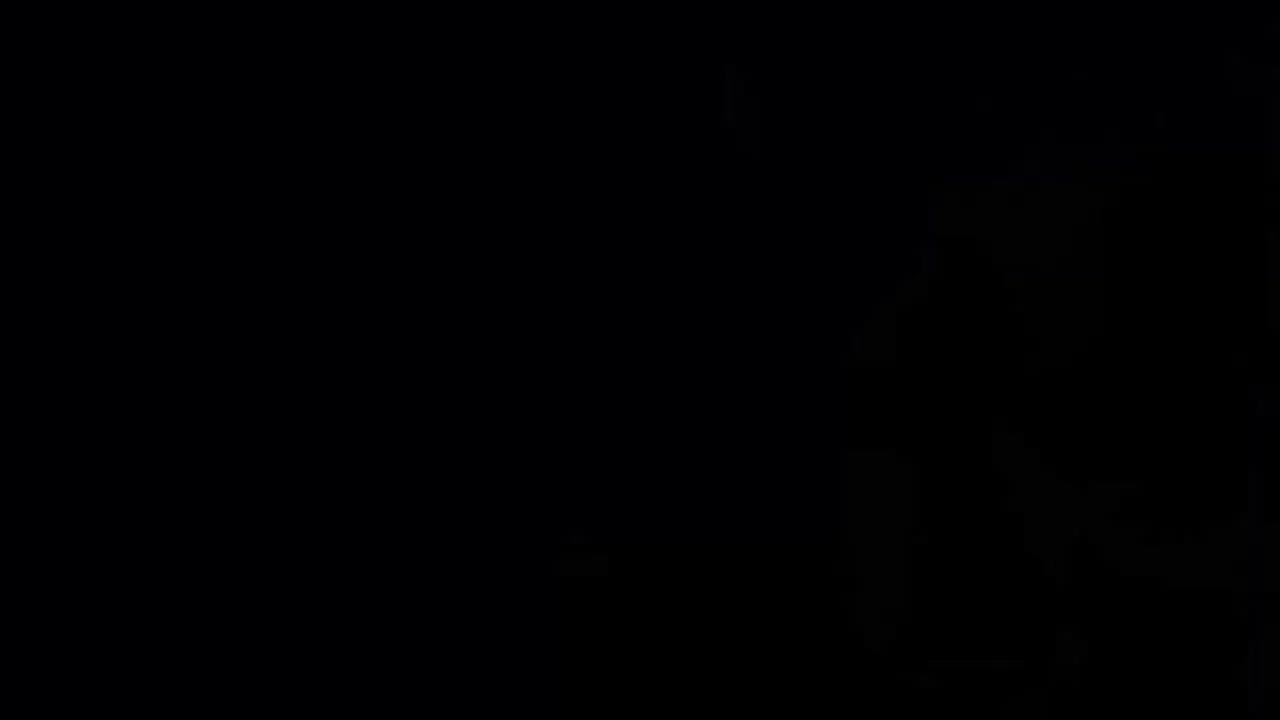

rank=2 | score=0.6019 | L24_V044/015 | pts=3.329s | frame_idx=88


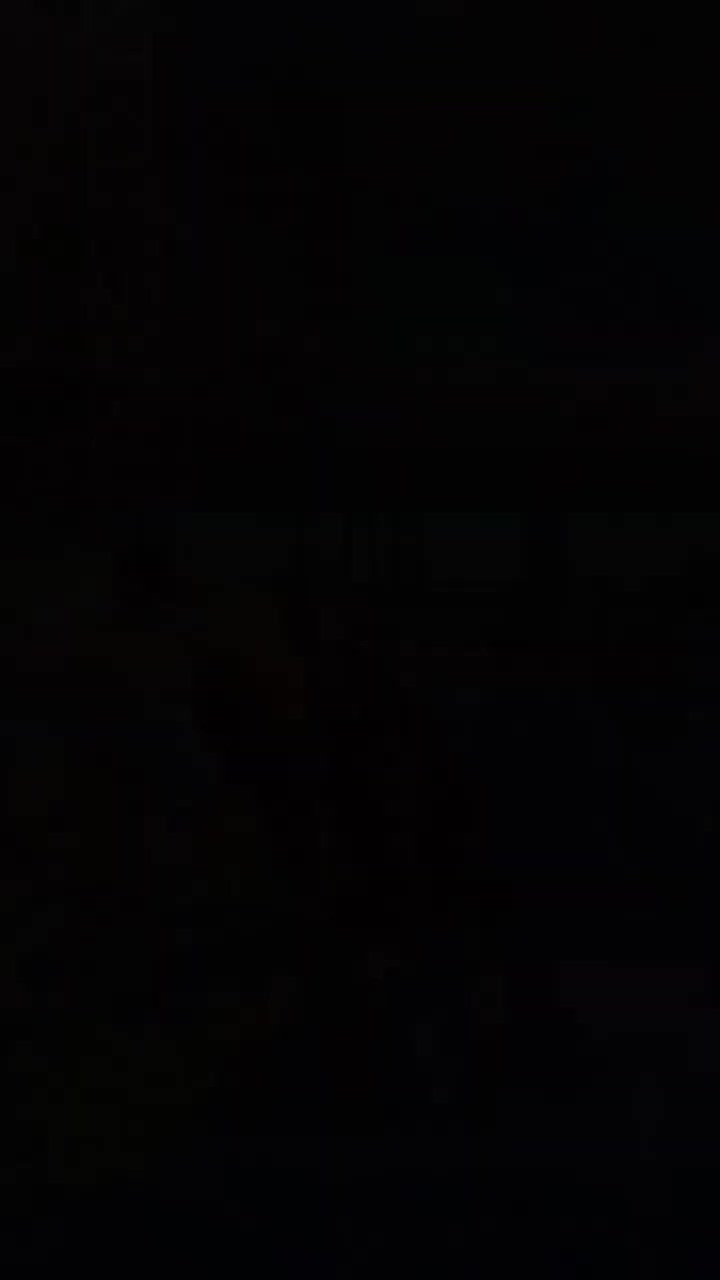

rank=3 | score=0.5865 | L25_V040/010 | pts=29.163s | frame_idx=874


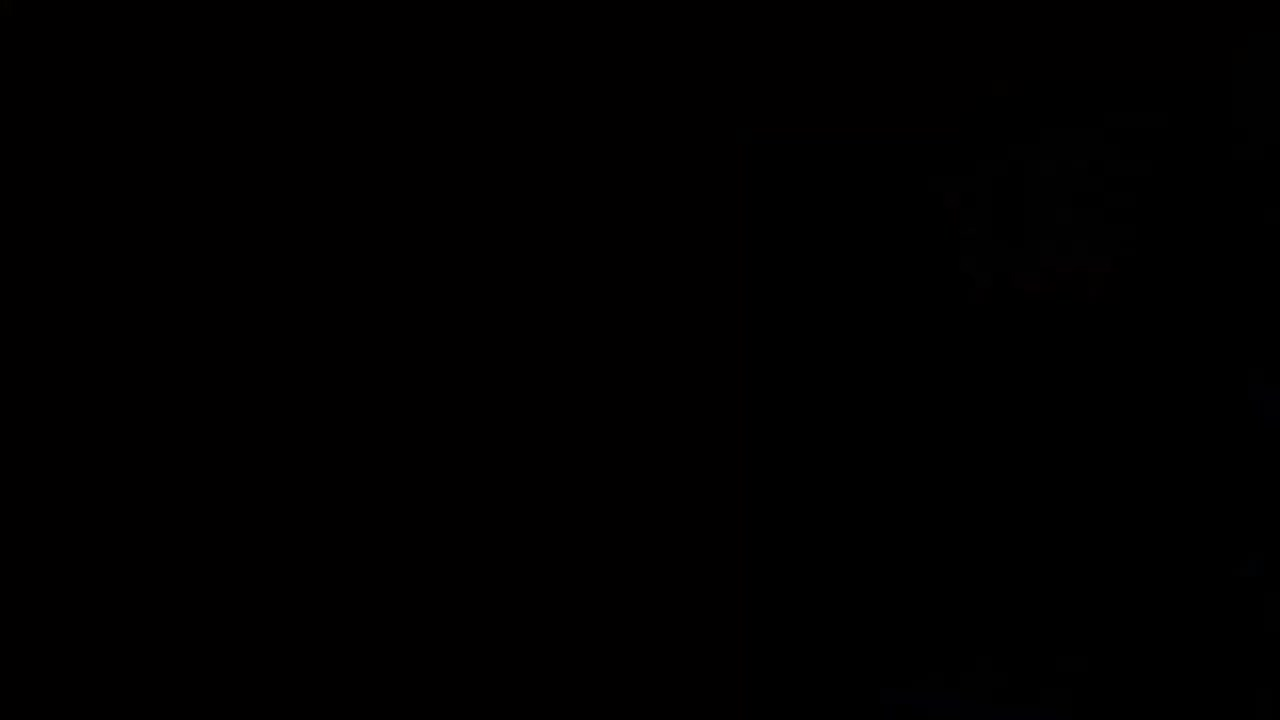

rank=4 | score=0.5757 | L25_V017/259 | pts=816.382s | frame_idx=24466


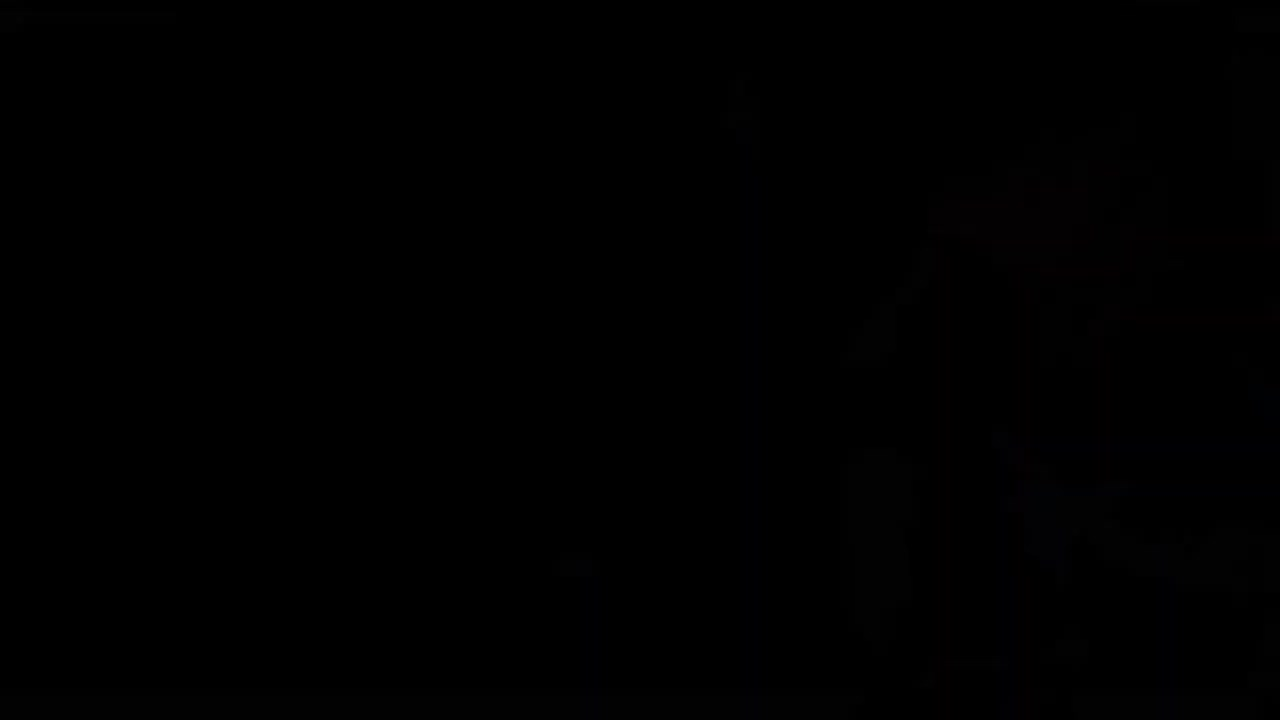

rank=5 | score=0.5740 | L25_V008/010 | pts=29.062s | frame_idx=871


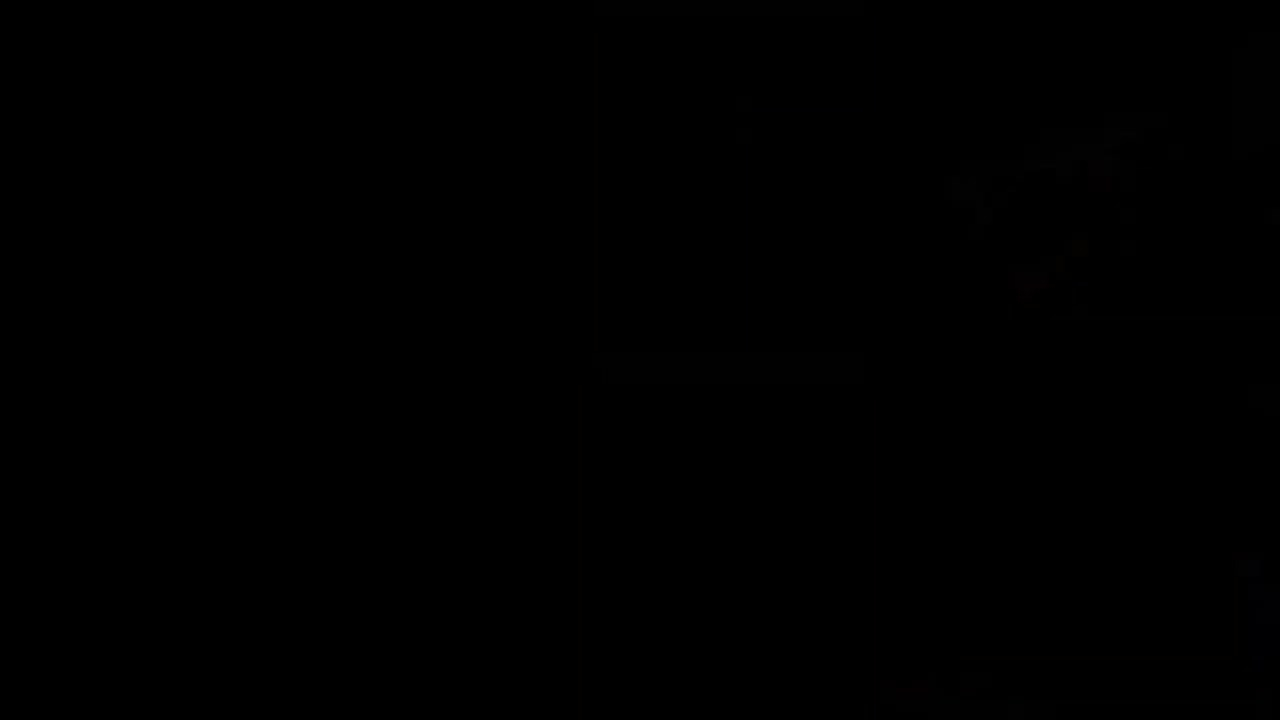

In [21]:
# ============================================================
# 18. SMOKE TEST QUERY
# ============================================================

TEST_QUERY = (
    "Một người đang đứng gần một tòa nhà vào ban đêm."
)

test_results = search_qwen(
    TEST_QUERY,
    top_k=10,
)

show_results(
    test_results,
    max_images=5,
)

In [22]:
# ============================================================
# 19. FINAL SUMMARY
# ============================================================

progress = read_json(
    QWEN_PROGRESS_PATH,
    default={},
)

faiss_meta = read_json(
    FAISS_META_PATH,
    default={},
)

summary = {
    "master": str(MASTER_PATH),
    "rows": int(N),
    "videos": int(
        master[
            "video_id"
        ].nunique()
    ),
    "model": QWEN_MODEL_ID,
    "full_dim": int(FULL_EMBED_DIM),
    "index_dim": int(INDEX_DIM),
    "image_source_during_embedding": "local_ssd",
    "embedding_completed": int(
        progress.get(
            "completed",
            0,
        )
    ),
    "final_batch_size": progress.get(
        "final_batch_size",
        progress.get(
            "last_batch_size"
        ),
    ),
    "average_qwen_images_per_second": progress.get(
        "average_qwen_images_per_second"
    ),
    "embedding_path": str(
        QWEN_EMBED_PATH
    ),
    "embedding_size_mib": round(
        QWEN_EMBED_PATH.stat().st_size
        / 1024**2,
        2,
    ),
    "faiss_path": str(
        FAISS_PATH
    ),
    "faiss_size_mib": round(
        FAISS_PATH.stat().st_size
        / 1024**2,
        2,
    ),
    "faiss_ntotal": int(
        faiss_index.ntotal
    ),
    "master_fingerprint": MASTER_FINGERPRINT,
    "qwen_repo_commit": QWEN_REPO_COMMIT,
}

print(
    json.dumps(
        summary,
        ensure_ascii=False,
        indent=2,
    )
)

assert summary[
    "embedding_completed"
] == N

assert summary[
    "faiss_ntotal"
] == N

print()
print(
    "QWEN EMBEDDING + FAISS STAGE: COMPLETE"
)

{
  "master": "/content/drive/MyDrive/data/retrieval-artifacts/master_keyframes.parquet",
  "rows": 177321,
  "videos": 873,
  "model": "Qwen/Qwen3-VL-Embedding-2B",
  "full_dim": 2048,
  "index_dim": 1024,
  "image_source_during_embedding": "local_ssd",
  "embedding_completed": 177321,
  "final_batch_size": 32,
  "average_qwen_images_per_second": 13.69967724597893,
  "embedding_path": "/content/drive/MyDrive/data/retrieval-artifacts/qwen3_vl_embedding_1024d.npy",
  "embedding_size_mib": 346.33,
  "faiss_path": "/content/drive/MyDrive/data/retrieval-artifacts/qwen3_vl_1024d.index",
  "faiss_size_mib": 692.66,
  "faiss_ntotal": 177321,
  "master_fingerprint": "6e9f6626b8cd1c1223d3ece8fd8cf33509f76d30d2cbd4af029d7d4544eee9c9",
  "qwen_repo_commit": "393e2978d27852b0d0230d6994f37f9c15bed73c"
}

QWEN EMBEDDING + FAISS STAGE: COMPLETE


# Final artifacts

Sau khi notebook hoàn tất:

```text
/content/drive/MyDrive/data/retrieval-artifacts/
├── master_keyframes.parquet
├── qwen3_vl_embedding_1024d.npy
├── qwen3_vl_embedding_1024d.progress.json
├── qwen3_vl_embedding_1024d.manifest.json
├── qwen3_vl_1024d.index
└── qwen3_vl_1024d.index.meta.json
```

## Khi Colab disconnect

Local keyframes trong `/content` sẽ mất. Khi chạy notebook lại:

1. ZIP được copy/extract lại từ Drive.
2. `master` được remap lại sang local.
3. Embedding đọc `progress.json`.
4. Tiếp tục từ `completed`.
5. Không cần tính lại phần đã checkpoint.

Nếu muốn cố ý rebuild hoàn toàn:

```python
FORCE_REBUILD_EMBEDDINGS = True
```

Nếu chỉ muốn extract lại local cache trong cùng session:

```python
FORCE_REEXTRACT_LOCAL = True
```

## Khi theo dõi GPU

Có thể mở terminal/cell khác:

```bash
watch -n 1 nvidia-smi
```

Sau khi chuyển sang local SSD, `GPU-Util` không nên còn ở `0%` gần như liên tục như khi đọc hàng trăm nghìn file trực tiếp từ Drive.